# Retail Customer Analytics

**Benjamin Dwomoh** · MSc Data Analytics coursework

Analyse transaction patterns, describe customer value and explore segments that could inform marketing hypotheses.

This portfolio edition revises my submitted coursework for reproducibility and clearer interpretation.

Run the notebook from this repository folder. Place the dataset in `data/` as described in `data/README.md`.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (8, 4.5)})
DATA_PATH = Path("data") / 'Online Retail.xlsx'
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Place the dataset at {DATA_PATH.resolve()}; see data/README.md")

## Load and inspect the data

The dataset was supplied for coursework. The original source is UCI Online Retail.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import seaborn as sns
bd = pd.read_excel(DATA_PATH)
print("Original shape:", bd.shape)
display(bd.head())

Original shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
numeric = ['Quantity', 'UnitPrice']
categorical = ['InvoiceNo', 'StockCode', 'Description', 'CustomerID', 'Country']
temporal = ['InvoiceDate']
print('Numerical:', numeric)
print('Categorical:', categorical)
print('Temporal:', temporal)
display(bd[numeric].describe().T)
for col in numeric:
    c = bd[col].dropna()
    print(col, {'mean':c.mean(), 'median':c.median(), 'mode':c.mode().iloc[0],
                'range':c.max()-c.min(), 'variance':c.var(), 'std':c.std(),
                'Q1':c.quantile(.25), 'Q3':c.quantile(.75), 'IQR':c.quantile(.75)-c.quantile(.25)})

Numerical: ['Quantity', 'UnitPrice']
Categorical: ['InvoiceNo', 'StockCode', 'Description', 'CustomerID', 'Country']
Temporal: ['InvoiceDate']
Quantity {'mean': np.float64(9.55224954743324), 'median': np.float64(3.0), 'mode': np.int64(1), 'range': np.int64(161990), 'variance': np.float64(47559.391409298616), 'std': np.float64(218.08115785023386), 'Q1': np.float64(1.0), 'Q3': np.float64(10.0), 'IQR': np.float64(9.0)}
UnitPrice {'mean': np.float64(4.611113626088514), 'median': np.float64(2.08), 'mode': np.float64(1.25), 'range': np.float64(50032.06), 'variance': np.float64(9362.469164421023), 'std': np.float64(96.75985306117937), 'Q1': np.float64(1.25), 'Q3': np.float64(4.13), 'IQR': np.float64(2.88)}


,count,mean,std,min,25%,50%,75%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,1.00,3.00,10.00,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0


## Clean transactions

Exclude duplicates, missing customer identifiers, cancellations and non-positive purchases. These choices define a purchase-only subset and do not measure net revenue after returns.

In [5]:
data_before = {
    'rows': len(bd), 'duplicates': int(bd.duplicated().sum()),
    'missing_customer_id': int(bd['CustomerID'].isna().sum()),
    'cancelled_invoices': int(bd['InvoiceNo'].astype(str).str.upper().str.startswith('C').sum()),
    'nonpositive_quantity': int((bd['Quantity'] <= 0).sum()),
    'nonpositive_price': int((bd['UnitPrice'] <= 0).sum())}
display(pd.Series(data_before, name='count'))

ga = bd.drop_duplicates().copy()
ga['InvoiceDate'] = pd.to_datetime(ga['InvoiceDate'], errors='coerce')
ga = ga.dropna(subset=['CustomerID', 'InvoiceDate', 'Description'])
ga = ga[~ga['InvoiceNo'].astype(str).str.upper().str.startswith('C')]
ga = ga[(ga['Quantity'] > 0) & (ga['UnitPrice'] > 0)]
ga['CustomerID'] = ga['CustomerID'].astype(int).astype(str)
ga['TotalPrice'] = ga['Quantity'] * ga['UnitPrice']
ga['InvoiceMonth'] = ga['InvoiceDate'].dt.to_period('M').astype(str)
ga['InvoiceDay'] = ga['InvoiceDate'].dt.day_name()
ga['InvoiceHour'] = ga['InvoiceDate'].dt.hour
print('Cleaned shape:', ga.shape)
display(ga.head())

Cleaned shape: (392692, 12)


rows                    541909
duplicates                5268
missing_customer_id     135080
cancelled_invoices        9288
nonpositive_quantity     10624
nonpositive_price         2517
Name: count, dtype: int64

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,InvoiceMonth,InvoiceDay,InvoiceHour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8


In [6]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder

## Build customer features

Aggregate historical recency, frequency and monetary value. These features describe the same period: the following supervised tasks reconstruct historical value, not future customer lifetime value.

In [7]:
snapshot = ga['InvoiceDate'].max() + pd.Timedelta(days=1)
customer = ga.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum'),
    UniqueProducts=('StockCode', 'nunique'),
    TotalQuantity=('Quantity', 'sum'),
    AvgUnitPrice=('UnitPrice', 'mean'),
    Country=('Country', lambda x: x.mode().iloc[0])
).reset_index()
customer['AvgQuantityPerInvoice'] = customer['TotalQuantity'] / customer['Frequency']
customer['AvgBasketValue'] = customer['Monetary'] / customer['Frequency']
display(customer.head())
print('Customer-level shape:', customer.shape)

scaled_demo = StandardScaler().fit_transform(customer[['Recency','Frequency']])
euclidean_example = np.linalg.norm(scaled_demo[0] - scaled_demo[1])
manhattan_example = np.abs(scaled_demo[0] - scaled_demo[1]).sum()
print('Scaled Euclidean distance between first two customers:', round(euclidean_example, 3))
print('Scaled Manhattan distance between first two customers:', round(manhattan_example, 3))

Customer-level shape: (4338, 10)
Scaled Euclidean distance between first two customers: 3.332
Scaled Manhattan distance between first two customers: 4.019


,CustomerID,Recency,Frequency,Monetary,UniqueProducts,TotalQuantity,AvgUnitPrice,Country,AvgQuantityPerInvoice,AvgBasketValue
0,12346,326,1,77183.60,1,74215,1.040000,United Kingdom,74215.000000,77183.600000
1,12347,2,7,4310.00,103,2458,2.644011,Iceland,351.142857,615.714286
2,12348,75,4,1797.24,22,2341,5.764839,Finland,585.250000,449.310000
3,12349,19,1,1757.55,73,631,8.289041,Italy,631.000000,1757.550000
4,12350,310,1,334.40,17,197,3.841176,Norway,197.000000,334.400000


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay, silhouette_score)

## Compare regression models

Compare Linear Regression and Random Forest at two split ratios. Errors and R-squared are measured on log(1 + historical monetary value). Related spending features from the same period make this easier than forecasting future value.

In [9]:
reg_features = ['Recency','Frequency','UniqueProducts','AvgUnitPrice','AvgQuantityPerInvoice','Country']
reg_target = 'Monetary'
X = customer[reg_features]
y = np.log1p(customer[reg_target])
num_features = ['Recency','Frequency','UniqueProducts','AvgUnitPrice','AvgQuantityPerInvoice']
cat_features = ['Country']
preprocess = ColumnTransformer([('num', StandardScaler(), num_features),
                                ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)])

def regression_experiment(test_size):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42)
    models = {
        'Linear Regression': LinearRegression(),
        'Random Forest': RandomForestRegressor(n_estimators=250, min_samples_leaf=3, random_state=42, n_jobs=-1)}
    rows, predictions = [], {}
    for name, estimator in models.items():
        pipe = Pipeline([('preprocess', preprocess), ('model', estimator)])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        rows.append({'Split':f'{int((1-test_size)*100)}/{int(test_size*100)}','Model':name,
                     'MAE':mean_absolute_error(y_test,pred),
                     'MSE':mean_squared_error(y_test,pred),
                     'RMSE':mean_squared_error(y_test,pred)**0.5,
                     'R2':r2_score(y_test,pred)})
        predictions[name] = (y_test, pred)
    return rows, predictions

rows80, pred80 = regression_experiment(.20)
rows70, pred70 = regression_experiment(.30)
reg_results = pd.DataFrame(rows80 + rows70)
display(reg_results.round(3))
best_reg_name = reg_results.sort_values(['R2','RMSE'], ascending=[False,True]).iloc[0]['Model']
print('Best regression model overall:', best_reg_name)

Best regression model overall: Random Forest


,Split,Model,MAE,MSE,RMSE,R2
0,80/20,Linear Regression,0.654,0.768,0.876,0.521
1,80/20,Random Forest,0.208,0.081,0.285,0.949
2,70/30,Linear Regression,0.668,0.949,0.974,0.416
3,70/30,Random Forest,0.219,0.113,0.336,0.931


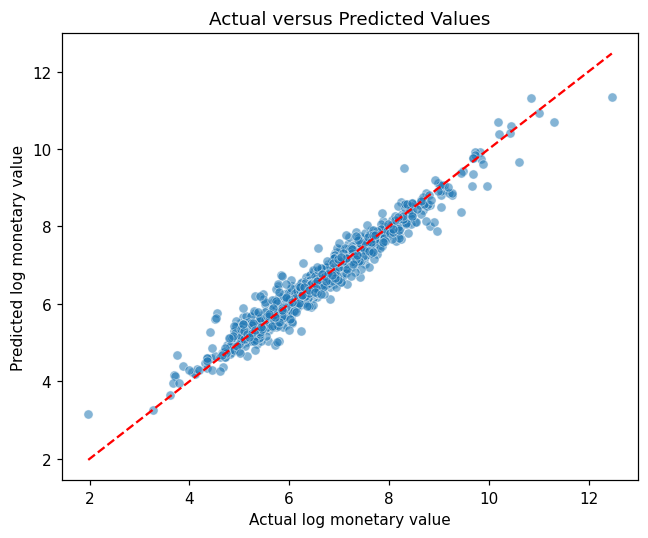

In [10]:
y_actual, y_pred = pred80['Random Forest']
plt.figure(figsize=(6,5)); sns.scatterplot(x=y_actual, y=y_pred, alpha=.55)
lims=[min(y_actual.min(),y_pred.min()),max(y_actual.max(),y_pred.max())]
plt.plot(lims,lims,'r--'); plt.xlabel('Actual log monetary value'); plt.ylabel('Predicted log monetary value')
plt.title('Actual versus Predicted Values'); plt.tight_layout()
plt.show()

## Classify historical customer value

Quantile tiers describe relative value within this sample. The tier thresholds are derived from the full sample for this descriptive exercise; production thresholds should be learned on training data and frozen.

Accuracy              0.795
Precision_weighted    0.796
Recall_weighted       0.795
F1_weighted           0.795
Name: Score, dtype: float64

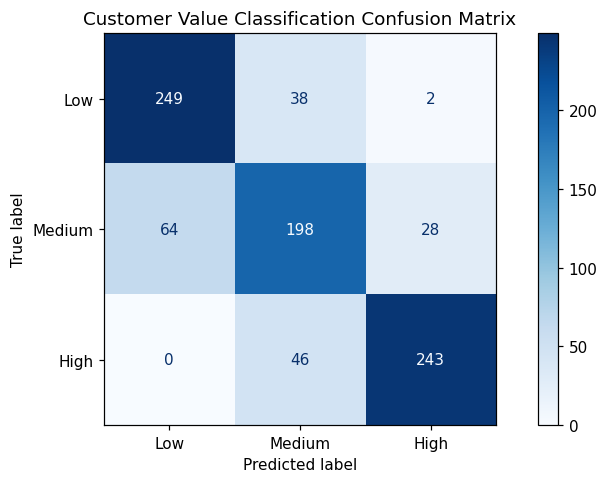

In [11]:
customer['ValueTier'] = pd.qcut(customer['Monetary'], 3, labels=['Low', 'Medium', 'High'])

features = ['Recency', 'Frequency', 'UniqueProducts', 'AvgUnitPrice', 'AvgQuantityPerInvoice', 'Country']

X_class = customer[features]
y_class = customer['ValueTier']

X_train, X_test, y_train, y_test = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

classifier = Pipeline([
    ('preparation', preprocess),
    ('classifier', LogisticRegression(
        max_iter=1500,
        class_weight='balanced',
        random_state=42
    ))
])

classifier.fit(X_train, y_train)
predictions = classifier.predict(X_test)

scores = {
    'Accuracy': accuracy_score(y_test, predictions),
    'Precision_weighted': precision_score(
        y_test, predictions, average='weighted'
    ),
    'Recall_weighted': recall_score(
        y_test, predictions, average='weighted'
    ),
    'F1_weighted': f1_score(
        y_test, predictions, average='weighted'
    )
}

display(pd.Series(scores, name='Score').round(3))

labels = ['Low', 'Medium', 'High']

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    labels=labels,
    display_labels=labels,
    cmap='Blues'
)

plt.title('Customer Value Classification Confusion Matrix')
plt.tight_layout()
plt.show()

## Explore customer segments

K-means uses log-transformed and standardised RFM features. Select k using silhouette scores; PCA is used only to display the clusters.

In [12]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

Selected clusters: 2


,k,inertia,silhouette
0,2,6483.589,0.433
1,3,4869.489,0.337
2,4,3938.603,0.337
3,5,3296.709,0.316
4,6,2855.526,0.313
5,7,2548.820,0.309
6,8,2336.341,0.303


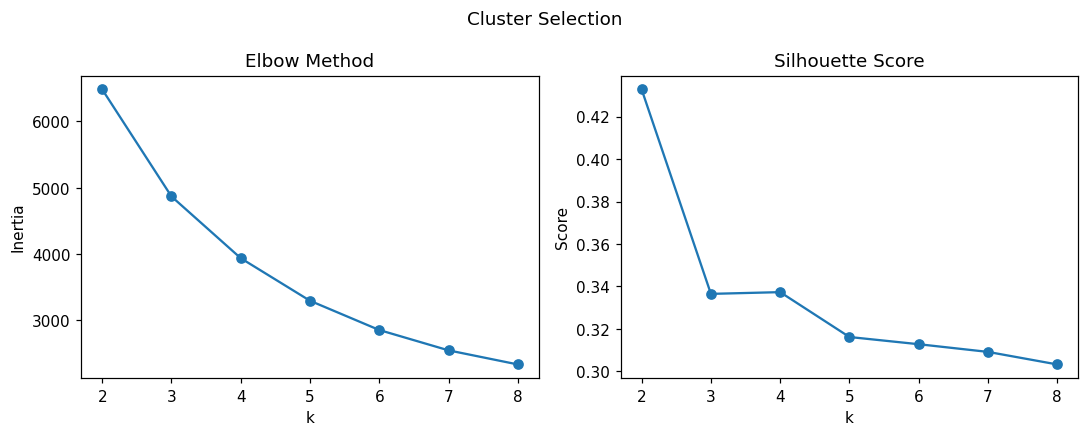

,Customers,Recency,Frequency,Monetary,MeanMonetary
Cluster,,,,,
0,2672,96.0,1.0,363.08,495.59
1,1666,16.0,6.0,2061.08,4539.60


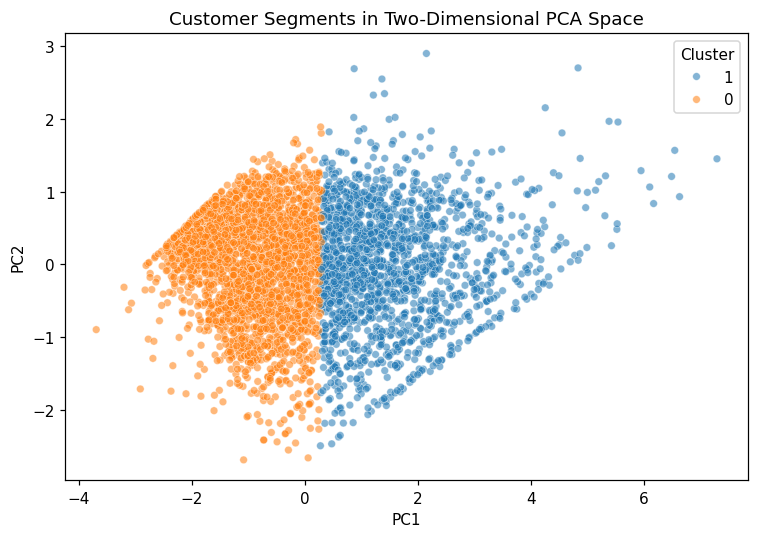

In [13]:
cluster_features = ['Recency','Frequency','Monetary']
cluster_data = np.log1p(customer[cluster_features])
cluster_scaled = StandardScaler().fit_transform(cluster_data)
inertias, silhouettes = [], []
for k in range(2,9):
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = km.fit_predict(cluster_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(cluster_scaled, labels))
cluster_selection = pd.DataFrame({'k':range(2,9),'inertia':inertias,'silhouette':silhouettes})
display(cluster_selection.round(3))
best_k = int(cluster_selection.loc[cluster_selection['silhouette'].idxmax(),'k'])
print('Selected clusters:', best_k)

fig, ax = plt.subplots(1,2,figsize=(10,4))
ax[0].plot(cluster_selection['k'],cluster_selection['inertia'],marker='o'); ax[0].set_title('Elbow Method'); ax[0].set_xlabel('k'); ax[0].set_ylabel('Inertia')
ax[1].plot(cluster_selection['k'],cluster_selection['silhouette'],marker='o'); ax[1].set_title('Silhouette Score'); ax[1].set_xlabel('k'); ax[1].set_ylabel('Score')
plt.suptitle('Cluster Selection'); plt.tight_layout(); plt.show()

kmeans = KMeans(n_clusters=best_k, n_init=30, random_state=42)
customer['Cluster'] = kmeans.fit_predict(cluster_scaled)
cluster_profile = customer.groupby('Cluster').agg(Customers=('CustomerID','count'), Recency=('Recency','median'),
    Frequency=('Frequency','median'), Monetary=('Monetary','median'), MeanMonetary=('Monetary','mean')).round(2)
display(cluster_profile)
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(cluster_scaled)
plot_df = pd.DataFrame({'PC1':coords[:,0],'PC2':coords[:,1],'Cluster':customer['Cluster'].astype(str)})
plt.figure(figsize=(7,5)); sns.scatterplot(data=plot_df,x='PC1',y='PC2',hue='Cluster',palette='tab10',alpha=.55,s=25)
plt.title('Customer Segments in Two-Dimensional PCA Space'); plt.tight_layout()
plt.show()

## Communicate business patterns

Compare monthly purchase revenue, products and countries. December 2011 is incomplete and must not be compared directly with complete months.

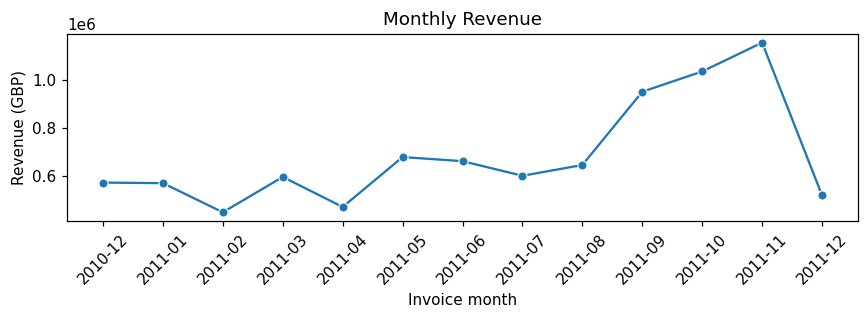

In [14]:
monthly = ga.groupby('InvoiceMonth', as_index=False)['TotalPrice'].sum()
plt.figure(figsize=(8,3)); sns.lineplot(data=monthly, x='InvoiceMonth', y='TotalPrice', marker='o')
plt.xticks(rotation=45); plt.title('Monthly Revenue'); plt.xlabel('Invoice month'); plt.ylabel('Revenue (GBP)'); plt.tight_layout()
plt.show()

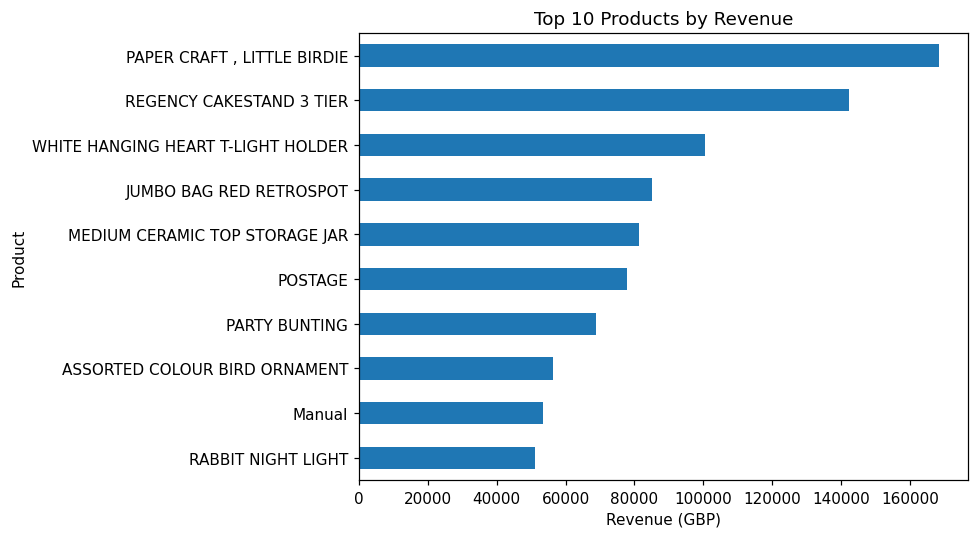

In [15]:
top_products = ga.groupby('Description')['TotalPrice'].sum().nlargest(10).sort_values()
plt.figure(figsize=(9,5)); top_products.plot(kind='barh'); plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (GBP)'); plt.ylabel('Product'); plt.tight_layout(); plt.show()

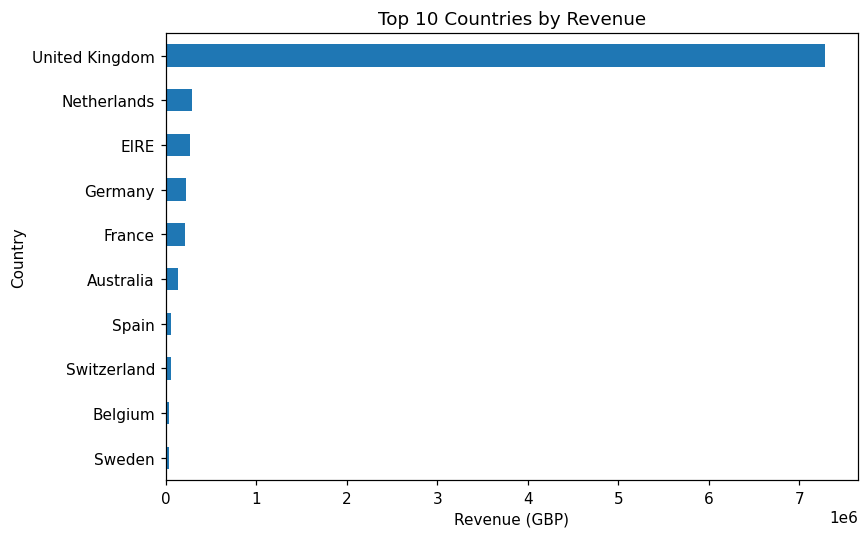

In [16]:
country_rev = ga.groupby('Country')['TotalPrice'].sum().nlargest(10).sort_values()
plt.figure(figsize=(8,5)); country_rev.plot(kind='barh'); plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue (GBP)'); plt.tight_layout(); plt.show()

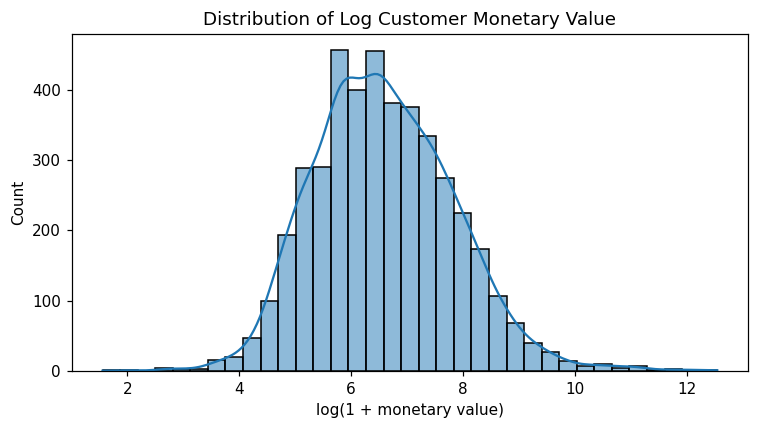

In [17]:
plt.figure(figsize=(7,4)); sns.histplot(np.log1p(customer['Monetary']), bins=35, kde=True)
plt.title('Distribution of Log Customer Monetary Value'); plt.xlabel('log(1 + monetary value)')
plt.tight_layout(); plt.show()

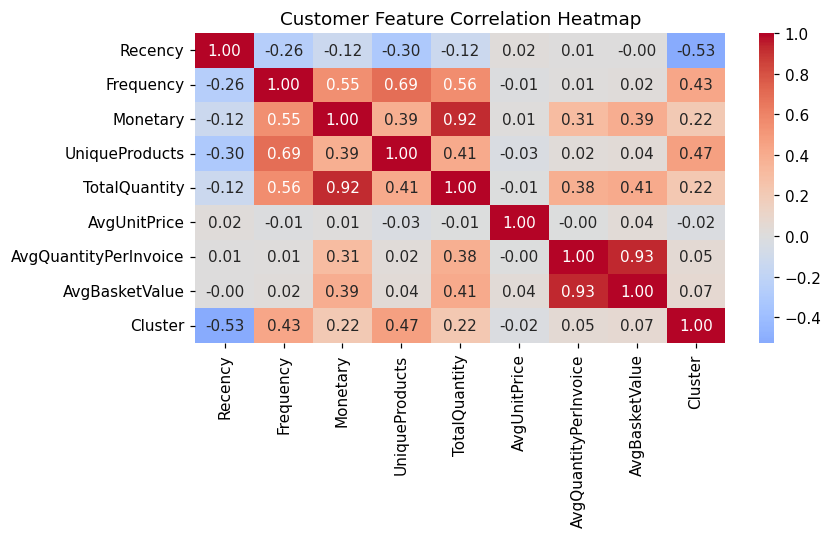

In [18]:
plt.figure(figsize=(8,5)); sns.heatmap(customer.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Customer Feature Correlation Heatmap'); plt.tight_layout(); plt.show()

## Interpretation and limitations

Use the cluster profiles to formulate retention or re-engagement hypotheses; no campaign lift or causal effect was tested. The UK dominates the source data. Missing-ID exclusions reduce coverage, and removing cancellations means reported revenue is purchase revenue rather than net revenue. Supervised results are same-period historical reconstruction, not a validated forecast. A future extension should use a time cutoff, derive features before it, define spending after it, and validate on later periods. RFM clustering is descriptive, and a silhouette score does not prove business usefulness.